# COS40007 - Portfolio Assessment 3
## Electrical grid stability: Random Forest, MLP and ANN classification

**Student:** Hoang Huu Hoan | **ID:** 105732188

**Engineering question:** How accurately do 11 operating parameters distinguish stable from
unstable simulated grid configurations, and how does the required ANN compare with Random
Forest and scikit-learn MLP?

This notebook contains all modelling and analysis code. Run all cells in order from this
directory using Python 3.12 and `requirements-lock.txt`. Paths are relative. The report and
`ASSISTANCE_LOG.md` disclose AI-generated implementation, execution, debugging and writing.
This is an assisted working analysis for student review; it is not represented as student-authored code.
Personal learning reflection and Canvas details are deferred in `SUBMISSION_TODO.md` at the user's request.

**Roadmap:** setup; data audit and fixed splits; five-fold traditional CV; ANN development;
frozen final refits; test comparison; persistence and independent reload; reflections and reproduction.
Results are added and verified at each actual development phase.

## 1. Setup and declared evaluation protocol

Use the Portfolio 2 stratified 70/30 split (seed 42): 7,000 development and 3,000 test rows.
This is a **previously inspected benchmark**: Task 1 explored all data and Task 2 examined
this test split. It is not untouched external validation. All new configuration and epoch
decisions use development evidence only. No test-based revisions are permitted.

Traditional CV uses five shuffled stratified folds (seed 42), with scaling inside each fold's
pipeline. Report sample fold SD (`ddof=1`), not confidence intervals. ANN trials use a fixed
5,600/1,400 stratified fit/validation split (seed 43), with scaling fitted on the 5,600 only.
Run one 10-epoch batch-32 pilot, then fresh batch-16/32/64 trials capped at 50 epochs, with
early stopping (patience 10, restore best weights) and LR reduction (factor 0.5, patience 5).
ANN-1 is batch 32 and ANN-2 is batch 64, regardless of the batch-16 development score.

Freeze each core ANN's best validation-loss epoch and all model settings before final test
inference. Refit all four models on identical scaled 7,000-row development inputs, with a
fresh common scaler. Final ANNs start afresh, use fixed initial Adam LR 0.001, and have no
validation callbacks; their schedules differ from trial schedules. Their saved histories and
`.h5` models refer to final refits. Required validation curves refer to development trials.
ANN CV is not performed; validation scores must not be labelled CV.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
os.environ['OMP_NUM_THREADS'] = '2'
import sys, json, hashlib, pickle, warnings, time, copy, platform, subprocess, importlib.metadata
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import h5py
import sklearn
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay, log_loss)
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits
import tensorflow as tf
from tensorflow import keras
from IPython.display import display, Markdown
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)
tf.config.experimental.enable_op_determinism()
threadpool_limits(limits=2)
SEED, VALIDATION_SEED = 42, 43
keras.utils.set_random_seed(SEED)
ROOT = Path.cwd()
assert (ROOT / 'data/Data_for_UCI_named.csv').is_file(), 'Run from portfolio_task3/'
for folder in ['models', 'results', 'figures', 'report']:
    (ROOT / folder).mkdir(exist_ok=True)
FEATURES = ['tau1','tau2','tau3','tau4','p2','p3','p4','g1','g2','g3','g4']
CLASS_MAP = {'stable': 0, 'unstable': 1}
CLASS_NAMES = ['stable', 'unstable']
REPOSITORY = 'https://github.com/henryhoang207/COS40007-Porfollio-Task'
VERSIONS = {p: importlib.metadata.version(p) for p in
            ['tensorflow','keras','scikit-learn','numpy','pandas','matplotlib','seaborn','h5py','nbformat','nbclient']}
VERSIONS['python'] = platform.python_version()
print(json.dumps(VERSIONS, indent=2))
print('CPU devices:', tf.config.list_physical_devices('CPU'))
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 180, 'font.size': 10})
def save_json(path, value):
    path.write_text(json.dumps(value, indent=2, allow_nan=False), encoding='utf-8')
def show_table(frame, filename=None):
    if filename:
        frame.to_csv(ROOT / 'results' / filename, index=False)
    display(frame)
def save_figure(name):
    plt.gcf().savefig(ROOT / 'figures' / name, bbox_inches='tight')
    plt.show()
    plt.close()
def explain(text):
    display(Markdown(text))
def build_ann(seed=SEED):
    keras.utils.set_random_seed(seed)
    model = keras.Sequential([
        keras.Input(shape=(len(FEATURES),), name='grid_features'),
        keras.layers.Dense(64, activation='relu', name='dense_64'),
        keras.layers.Dropout(0.2, name='dropout_1'),
        keras.layers.Dense(32, activation='relu', name='dense_32'),
        keras.layers.Dropout(0.2, name='dropout_2'),
        keras.layers.Dense(16, activation='relu', name='dense_16'),
        keras.layers.Dense(2, activation='softmax', name='class_probabilities'),
    ], name='grid_stability_ann')
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model
smoke = build_ann()
smoke_x = np.zeros((3, 11), dtype=np.float32)
smoke_before = smoke(smoke_x, training=False).numpy()
import tempfile
with tempfile.TemporaryDirectory() as smoke_dir:
    smoke_path = Path(smoke_dir) / 'whole_model.h5'
    smoke.save(smoke_path)
    with h5py.File(smoke_path) as h:
        assert 'model_config' in h.attrs and 'model_weights' in h
    smoke_loaded = keras.models.load_model(smoke_path)
    np.testing.assert_allclose(smoke_before, smoke_loaded(smoke_x, training=False).numpy(), atol=1e-6, rtol=1e-6)
assert smoke.count_params() == 3410
smoke.summary()
save_json(ROOT / 'results/setup_verification.json', {
    'versions': VERSIONS, 'whole_model_hdf5_roundtrip': True,
    'ann_parameter_count': smoke.count_params(), 'cpu_training': True,
    'tensorflow_deterministic_ops': True, 'oneDNN_enabled': False,
})
print('PHASE 1 PASSED: imports, CPU, required architecture, whole-model HDF5 save/load.')

{
  "tensorflow": "2.20.0",
  "keras": "3.15.1",
  "scikit-learn": "1.7.2",
  "numpy": "2.2.6",
  "pandas": "2.3.3",
  "matplotlib": "3.10.7",
  "seaborn": "0.13.2",
  "h5py": "3.15.1",
  "nbformat": "5.10.4",
  "nbclient": "0.10.2",
  "python": "3.12.10"
}
CPU devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


Model: "grid_stability_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_64 (Dense)                │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ class_probabilities (Dense)     │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,410 (13.32 KB)

 Trainable params: 3,410 (13.32 KB)

 Non-trainable params: 0 (0.00 B)

PHASE 1 PASSED: imports, CPU, required architecture, whole-model HDF5 save/load.


## 2. Data audit, continuity and leakage prevention

The CSV is an unchanged copy of Portfolio 2. Each row is an independent simulated four-node
grid configuration, not a time-series sample. `stabf` is already categorical. Exclude `stab`
because its sign determines the answer, and `p1` because it equals `-(p2+p3+p4)`.
Keep the same ordered 11 original predictors for every core model. No imputation, resampling,
feature engineering or row removal is justified by the audit. Majority-only accuracy is 63.8%.
UCI attribution and CC BY 4.0 licensing are retained in `data/README.md`.

In [2]:
data_path = ROOT / 'data/Data_for_UCI_named.csv'
data_hash = hashlib.sha256(data_path.read_bytes()).hexdigest()
expected_hash = json.loads((ROOT / 'data/source_manifest.json').read_text())['sha256']
assert data_hash == expected_hash
df = pd.read_csv(data_path)
assert df.shape == (10000, 14)
assert set(df.stabf.unique()) == set(CLASS_MAP)
assert df.isna().sum().sum() == 0
assert df.duplicated().sum() == 0
assert df[FEATURES].duplicated().sum() == 0
assert np.isfinite(df.select_dtypes('number').to_numpy()).all()
assert (df.stabf == np.where(df.stab > 0, 'unstable', 'stable')).all()
assert np.allclose(df.p1, -(df.p2+df.p3+df.p4), atol=1e-10)
for cols, low, high in [(['tau1','tau2','tau3','tau4'],.5,10),
                        (['g1','g2','g3','g4'],.05,1), (['p2','p3','p4'],-2,-.5)]:
    assert df[cols].ge(low).all().all() and df[cols].le(high).all().all()
X = df.loc[:, FEATURES].copy()
y = df.stabf.map(CLASS_MAP).astype('int64')
assert list(X.columns) == FEATURES
assert set(FEATURES).isdisjoint({'stab','stabf','p1'})
counts = df.stabf.value_counts().reindex(CLASS_NAMES)
assert counts.tolist() == [3620,6380]
show_table(pd.DataFrame({'class':counts.index,'code':[0,1], 'count':counts.values,
                         'proportion':counts.values/len(df)}), 'class_distribution.csv')
show_table(df.head())
save_json(ROOT / 'results/data_audit.json', {
    'shape': list(df.shape), 'sha256': data_hash, 'missing_cells': 0,
    'duplicate_rows': 0, 'duplicate_predictors': 0, 'finite_numeric_values': True,
    'label_sign_agrees': True, 'power_balance_agrees': True,
    'features': FEATURES, 'class_map': CLASS_MAP, 'rows_retained': len(df),
})
print('CSV SHA-256:', data_hash)

,class,code,count,proportion
0,stable,0,3620,0.362
1,unstable,1,6380,0.638


,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab,stabf
0,2.959060,3.079885,8.381025,9.780754,3.763085,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347,unstable
1,9.304097,4.902524,3.047541,1.369357,5.067812,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957,stable
2,8.971707,8.848428,3.046479,1.214518,3.405158,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471,unstable
3,0.716415,7.669600,4.486641,2.340563,3.963791,-1.027473,-1.938944,-0.997374,0.446209,0.976744,0.929381,0.362718,0.028871,unstable
4,3.134112,7.608772,4.943759,9.857573,3.525811,-1.125531,-1.845975,-0.554305,0.797110,0.455450,0.656947,0.820923,0.049860,unstable


CSV SHA-256: 7afc3154fed9cd65258b3403b60381fe6b0d832bf817a1ea4866395d05a84a83


In [3]:
dev_idx, test_idx = train_test_split(np.arange(len(df)), test_size=0.30,
                                   stratify=y, random_state=SEED)
fit_idx, val_idx = train_test_split(dev_idx, test_size=0.20,
                                  stratify=y.iloc[dev_idx], random_state=VALIDATION_SEED)
X_dev, X_test = X.iloc[dev_idx], X.iloc[test_idx]
y_dev, y_test = y.iloc[dev_idx], y.iloc[test_idx]
X_fit, X_val = X.iloc[fit_idx], X.iloc[val_idx]
y_fit, y_val = y.iloc[fit_idx], y.iloc[val_idx]
assert (len(dev_idx),len(test_idx),len(fit_idx),len(val_idx)) == (7000,3000,5600,1400)
assert not (set(dev_idx) & set(test_idx))
assert not (set(fit_idx) & set(val_idx))
assert set(fit_idx) | set(val_idx) == set(dev_idx)
split_rows = []
for split_name, indices in [('fit',fit_idx),('validation',val_idx),('test',test_idx)]:
    split_rows.extend({'row_index':int(i), 'role':split_name, 'split_position':pos,
                       'target':int(y.iloc[i])} for pos,i in enumerate(indices))
split_manifest = pd.DataFrame(split_rows).sort_values('row_index')
assert split_manifest.row_index.nunique() == len(df)
show_table(pd.DataFrame([{'split':name, 'X_shape':str(xx.shape), 'y_shape':str(yy.shape),
                         'stable':int((yy==0).sum()),'unstable':int((yy==1).sum())}
                        for name,xx,yy in [('development',X_dev,y_dev),('ANN fit',X_fit,y_fit),
                                          ('ANN validation',X_val,y_val),('test',X_test,y_test)]]),
           'split_shapes.csv')
split_manifest.to_csv(ROOT / 'results/split_indices.csv', index=False)
pd.DataFrame({'split_position':range(len(dev_idx)), 'row_index':dev_idx}).to_csv(
    ROOT / 'results/development_order.csv', index=False)
trial_scaler = StandardScaler().fit(X_fit)
X_fit_scaled = trial_scaler.transform(X_fit).astype('float32')
X_val_scaled = trial_scaler.transform(X_val).astype('float32')
assert trial_scaler.n_samples_seen_ == 5600
np.testing.assert_allclose(trial_scaler.mean_, X_fit.mean().to_numpy(), atol=1e-12)
save_json(ROOT / 'results/split_verification.json', {
    'development_rows':7000,'test_rows':3000,'ann_fit_rows':5600,'ann_validation_rows':1400,
    'complete_disjoint_roles': True, 'trial_scaler_fit_rows':5600,
    'split_seed':SEED,'validation_seed':VALIDATION_SEED,
    'previously_inspected_benchmark':True,
})
print('PHASE 2 PASSED: hash, audit, exclusions, dimensions, split coverage and fit-only scaler.')

,split,X_shape,y_shape,stable,unstable
0,development,"(7000, 11)","(7000,)",2534,4466
1,ANN fit,"(5600, 11)","(5600,)",2027,3573
2,ANN validation,"(1400, 11)","(1400,)",507,893
3,test,"(3000, 11)","(3000,)",1086,1914


PHASE 2 PASSED: hash, audit, exclusions, dimensions, split coverage and fit-only scaler.


## 3. Part A - traditional classifiers and five-fold CV

Random Forest uses 300 trees and otherwise standard classifier defaults (seed 42).
MLP uses hidden layers `(64,32,16)`, ReLU, Adam, learning rate 0.001, batch size `auto`
(200 here), no internal validation early stopping, and `max_iter=500`. Each fold's scaler
learns only from that fold's 5,600 training rows. Scaling is included for RF for protocol
consistency, although affine scaling is not normally needed for a tree ensemble.

These are fixed configurations, not an extensive tuning search. MLP convergence warnings
and loss diagnostics are recorded. Iteration limits are changed only if the diagnostics
justify a bounded development-only repair, documented before test inference.

RF fold 1: accuracy=0.9243, F1=0.9238, iterations=None, fit=14.4s


RF fold 2: accuracy=0.9129, F1=0.9125, iterations=None, fit=15.0s


RF fold 3: accuracy=0.9086, F1=0.9081, iterations=None, fit=16.3s


RF fold 4: accuracy=0.9221, F1=0.9213, iterations=None, fit=16.1s


RF fold 5: accuracy=0.9164, F1=0.9156, iterations=None, fit=14.1s


...

MLP fold 3: accuracy=0.9529, F1=0.9529, iterations=132, fit=25.6s


MLP fold 4: accuracy=0.9629, F1=0.9627, iterations=128, fit=24.8s


MLP fold 5: accuracy=0.9493, F1=0.9491, iterations=146, fit=22.3s


,model,fold,accuracy,weighted_f1,train_rows,validation_rows,fit_seconds,iterations
0,RF,1,0.924286,0.923754,5600,1400,14.409556,NaN
1,RF,2,0.912857,0.912504,5600,1400,15.002156,NaN
2,RF,3,0.908571,0.908114,5600,1400,16.293010,NaN
3,RF,4,0.922143,0.921334,5600,1400,16.051757,NaN
4,RF,5,0.916429,0.915606,5600,1400,14.070348,NaN
5,MLP,1,0.957143,0.957087,5600,1400,29.856212,132.0
6,MLP,2,0.948571,0.948657,5600,1400,26.991139,129.0
7,MLP,3,0.952857,0.952877,5600,1400,25.586074,132.0
8,MLP,4,0.962857,0.962707,5600,1400,24.786935,128.0
9,MLP,5,0.949286,0.949092,5600,1400,22.313745,146.0


,model,cv_accuracy_mean,cv_accuracy_sd,cv_weighted_f1_mean,cv_weighted_f1_sd
0,MLP,0.954143,0.005942,0.954084,0.005899
1,RF,0.916857,0.006480,0.916262,0.006380


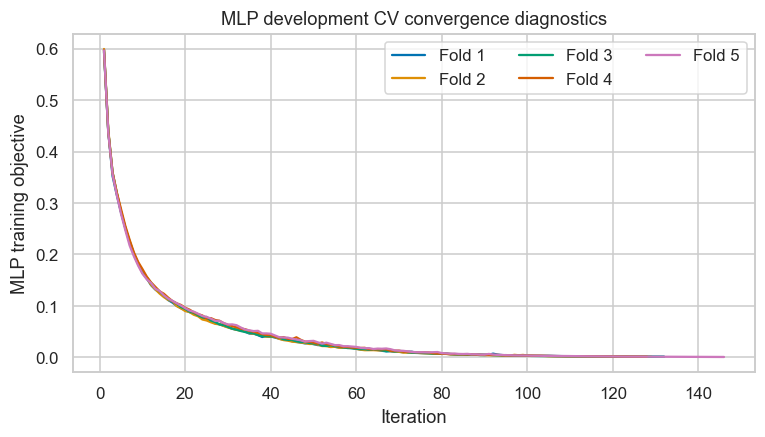

**Development evidence:** MLP has the higher mean CV accuracy. RF: 91.69% +/- 0.65%; MLP: 95.41% +/- 0.59% (sample fold SD). Fold variability is not a confidence interval. No test predictions have been used. MLP loss convergence is an optimisation diagnostic, not proof of good generalisation. The fixed iteration limit was retained after checking warnings.

PHASE 3 PASSED: ten fold fits, fold-local scaler checks, finite metrics and convergence diagnostics.


In [4]:
traditional_specs = {
    'RF': RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=2),
    'MLP': MLPClassifier(hidden_layer_sizes=(64,32,16), activation='relu', solver='adam',
                         learning_rate_init=0.001, max_iter=500, random_state=SEED),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
fold_partitions = list(cv.split(X_dev,y_dev))
cv_rows, cv_warnings, mlp_diagnostics, fold_manifest = [], [], [], []
for fold, (tr,va) in enumerate(fold_partitions,1):
    assert not (set(dev_idx[tr]) & set(dev_idx[va]))
    for pos in va:
        fold_manifest.append({'row_index':int(dev_idx[pos]), 'validation_fold':fold})
for name,spec in traditional_specs.items():
    for fold,(tr,va) in enumerate(fold_partitions,1):
        model = Pipeline([('scale',StandardScaler()),('model',clone(spec))])
        started = time.perf_counter()
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always', ConvergenceWarning)
            model.fit(X_dev.iloc[tr],y_dev.iloc[tr])
        elapsed = time.perf_counter()-started
        for warning in caught:
            cv_warnings.append({'model':name,'fold':fold,'category':warning.category.__name__,
                                'message':str(warning.message)})
        assert model['scale'].n_samples_seen_ == len(tr)
        np.testing.assert_allclose(model['scale'].mean_,X_dev.iloc[tr].mean().to_numpy(),atol=1e-12)
        prediction = model.predict(X_dev.iloc[va])
        row = {'model':name,'fold':fold,'accuracy':accuracy_score(y_dev.iloc[va],prediction),
               'weighted_f1':f1_score(y_dev.iloc[va],prediction,average='weighted'),
               'train_rows':len(tr),'validation_rows':len(va),'fit_seconds':elapsed,
               'iterations':getattr(model['model'],'n_iter_',None)}
        cv_rows.append(row)
        if name == 'MLP':
            loss = model['model'].loss_curve_
            mlp_diagnostics.append({'fold':fold,'iterations':model['model'].n_iter_,
                                    'final_loss':float(loss[-1]),'loss_curve':list(map(float,loss))})
        print(f'{name} fold {fold}: accuracy={row["accuracy"]:.4f}, F1={row["weighted_f1"]:.4f}, '
              f'iterations={row["iterations"]}, fit={elapsed:.1f}s',flush=True)
cv_frame = pd.DataFrame(cv_rows)
assert cv_frame.groupby('model').size().to_dict() == {'MLP':5,'RF':5}
assert np.isfinite(cv_frame[['accuracy','weighted_f1']].to_numpy()).all()
cv_summary = cv_frame.groupby('model').agg(
    cv_accuracy_mean=('accuracy','mean'),cv_accuracy_sd=('accuracy',lambda v:v.std(ddof=1)),
    cv_weighted_f1_mean=('weighted_f1','mean'),cv_weighted_f1_sd=('weighted_f1',lambda v:v.std(ddof=1)),
).reset_index()
best_traditional = cv_summary.sort_values('cv_accuracy_mean',ascending=False).iloc[0]['model']
show_table(cv_frame,'traditional_cv_results.csv')
show_table(cv_summary,'traditional_cv_summary.csv')
pd.DataFrame(fold_manifest).to_csv(ROOT / 'results/cv_fold_indices.csv',index=False)
save_json(ROOT / 'results/traditional_warnings.json',cv_warnings)
save_json(ROOT / 'results/mlp_convergence_diagnostics.json',mlp_diagnostics)
if cv_warnings:
    display(pd.DataFrame(cv_warnings))
assert not any(w['category']=='ConvergenceWarning' for w in cv_warnings), 'Inspect MLP diagnostics before continuing'
fig,ax = plt.subplots(figsize=(8,4))
for diag in mlp_diagnostics:
    ax.plot(range(1,len(diag['loss_curve'])+1),diag['loss_curve'],label=f'Fold {diag["fold"]}')
ax.set(xlabel='Iteration',ylabel='MLP training objective',title='MLP development CV convergence diagnostics')
ax.legend(ncol=3)
save_figure('mlp_cv_loss.png')
v = cv_summary.set_index('model')
explain(f'**Development evidence:** {best_traditional} has the higher mean CV accuracy. '
        f'RF: {v.loc["RF","cv_accuracy_mean"]:.2%} +/- {v.loc["RF","cv_accuracy_sd"]:.2%}; '
        f'MLP: {v.loc["MLP","cv_accuracy_mean"]:.2%} +/- {v.loc["MLP","cv_accuracy_sd"]:.2%} '
        '(sample fold SD). Fold variability is not a confidence interval. '
        'No test predictions have been used. MLP loss convergence is an optimisation diagnostic, '
        'not proof of good generalisation. The fixed iteration limit was retained after checking warnings.')
save_json(ROOT / 'results/traditional_verification.json',{
    'five_folds_each':True,'fold_local_scaling_verified':True,'convergence_warning_count':0,
    'mlp_max_iter':500,'best_traditional_by_cv_accuracy':best_traditional,
})
print('PHASE 3 PASSED: ten fold fits, fold-local scaler checks, finite metrics and convergence diagnostics.')